# CS-471: Machine Learning - CEP
## Live T20 Match Win Probability Prediction (2nd Innings)

**Student Name:** [Your Name]
**ID:** [Your ID]

### 🎯 Problem Statement
To build a probabilistic model that predicts the **Win Probability (%)** of the chasing team in a T20 match at any given ball of the second innings.

### 🧠 Logic & Engineering
1.  **Scope**: T20 Matches, 2nd Innings Only (Chase).
2.  **Target**: `is_chasing_team_winner` (1 if Chasing Team wins, 0 otherwise).
3.  **Features**: Derived real-time match state features (Runs Needed, RRR, Wickets in Hand, etc.).
4.  **Model**: XGBoost (Gradient Boosting) for calibrated probability estimation.
5.  **Evaluation**: Log Loss & Brier Score (Accuracy is insufficient for probability).

### 📂 Dataset
- **Source**: Cricsheet Merged Data
- **Path**: `D:\5th Semester\Machine Learning\CEA\ML CEA\cricsheet_merged_data.csv`


In [1]:
# 1. Import Libraries & Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Sklearn & Modeling
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, brier_score_loss, confusion_matrix, roc_curve
from sklearn.calibration import  calibration_curve

# Advanced Models
import xgboost as xgb
from catboost import CatBoostClassifier    

# Configuration
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
plt.style.use('fivethirtyeight')

print("✅ Libraries Imported Successfully")


✅ Libraries Imported Successfully


In [2]:
# 2. Data Loading & Filtering
## 2.1 Load Dataset
DATA_PATH = r'D:\5th Semester\Machine Learning\CEA\ML CEA\cricsheet_merged_data.csv'
df = pd.read_csv(DATA_PATH)
print(f"Original Shape: {df.shape}")


# Strict Filtering (T20 Only)
df['match_type'] = df['match_type'].astype(str).str.strip()
df = df[df['match_type'].isin(['T20', 'IT20'])] # Include IT20 just in case, or strict T20
print(f"T20 Only Shape: {df.shape}")

# Normalize Innings (The dataset uses '1st innings', '2nd innings')
# We need to map them to integers 1 and 2
inning_map = {
    '1st innings': 1, 
    '2nd innings': 2,
    1: 1, 
    2: 2,
    '1': 1,
    '2': 2
}
df['inning'] = df['inning'].map(inning_map)

# Drop any rows where inning couldn't be mapped (e.g., 'Super Over')
df.dropna(subset=['inning', 'winner'], inplace=True)
df['inning'] = df['inning'].astype(int)

# --- Target Preparation ---
# 1. Group by match_id to get 1st innings total
total_scores = df[df['inning'] == 1].groupby('match_id')['total_runs'].sum().reset_index()
total_scores.rename(columns={'total_runs': 'target_score'}, inplace=True)
total_scores['target_score'] += 1 # Target is +1

# 2. Merge Target into the main DF
df = pd.merge(df, total_scores, on='match_id', how='left')

# 3. Filter for 2nd Innings (Chase) Only
df_chase = df[df['inning'] == 2].copy()
df_chase.reset_index(drop=True, inplace=True)

# 4. Drop matches with no target (likely abandoned or data issue)
df_chase.dropna(subset=['target_score'], inplace=True)

print(f"2nd Innings (Chase) Rows: {df_chase.shape[0]}")
df_chase.head()



Original Shape: (10645589, 20)
T20 Only Shape: (2934061, 20)
2nd Innings (Chase) Rows: 1357895


,match_id,date,city,match_type,gender,team_a,team_b,winner,inning,batting_team,ball,batsman,non_striker,bowler,batsman_runs,extras,total_runs,is_wicket,player_out,dismissal_kind,target_score
0,1001349,2017-02-17,NaN,T20,male,Australia,Sri Lanka,Sri Lanka,2,Sri Lanka,0.1,N Dickwella,WU Tharanga,PJ Cummins,1,0,1,0,NaN,NaN,169
1,1001349,2017-02-17,NaN,T20,male,Australia,Sri Lanka,Sri Lanka,2,Sri Lanka,0.2,WU Tharanga,N Dickwella,PJ Cummins,0,1,1,0,NaN,NaN,169
2,1001349,2017-02-17,NaN,T20,male,Australia,Sri Lanka,Sri Lanka,2,Sri Lanka,0.3,N Dickwella,WU Tharanga,PJ Cummins,0,0,0,0,NaN,NaN,169
3,1001349,2017-02-17,NaN,T20,male,Australia,Sri Lanka,Sri Lanka,2,Sri Lanka,0.4,N Dickwella,WU Tharanga,PJ Cummins,0,0,0,0,NaN,NaN,169
4,1001349,2017-02-17,NaN,T20,male,Australia,Sri Lanka,Sri Lanka,2,Sri Lanka,0.5,N Dickwella,WU Tharanga,PJ Cummins,3,0,3,0,NaN,NaN,169


## 3.2 Ball-by-Ball Feature Engineering
We must calculate the state of the match *after every ball*.

**Derived Features:**
1.  **Current Score**: Cumulative sum of total runs.
2.  **Runs Needed**: `Target` - `Current Score`
3.  **Wickets Fallen**: Cumulative sum of `is_wicket`.
4.  **Wickets in Hand**: 10 - `Wickets Fallen`.
5.  **Balls Bowled**: (Over * 6) + Ball Number.
6.  **Balls Remaining**: 120 - `Balls Bowled`.
7.  **RRR (Required Run Rate)**: `Runs Needed` / `Overs Remaining`.
8.  **CRR (Current Run Rate)**: `Current Score` / `Overs Bowled`.


In [3]:

# 1. Cumulative Sums per Match
df_chase['current_score'] = df_chase.groupby('match_id')['total_runs'].cumsum()
df_chase['wickets_fallen'] = df_chase.groupby('match_id')['is_wicket'].cumsum()

# 2. Match State
df_chase['runs_needed'] = df_chase['target_score'] - df_chase['current_score']
df_chase['wickets_in_hand'] = 10 - df_chase['wickets_fallen']

# 3. Balls Parsing
# Assuming 'ball' column is float: 0.1, 0.2 ... 19.6
# We need strictly integer balls
df_chase['over'] = df_chase['ball'].astype(int)
df_chase['ball_num'] = ((df_chase['ball'] - df_chase['over']) * 10).round().astype(int)
df_chase['balls_bowled'] = (df_chase['over'] * 6) + df_chase['ball_num']
df_chase['balls_remaining'] = 120 - df_chase['balls_bowled']

# 4. Rates
# Avoid division by zero
df_chase['crr'] = (df_chase['current_score'] * 6) / df_chase['balls_bowled'].replace(0, 1) # run rate per over

# Required Run Rate
overs_remaining = df_chase['balls_remaining'] / 6
df_chase['rrr'] = df_chase['runs_needed'] / overs_remaining.replace(0, 0.1) # avoid div/0

# Clip impossible values (e.g., negative runs needed if they won already)
df_chase = df_chase[df_chase['balls_remaining'] > 0] # Filter out completed balls if any weirdness
df_chase['rrr'] = df_chase['rrr'].apply(lambda x: min(x, 36)) # Cap at 36 (impossible to exceed useful info)
df_chase['rrr'] = df_chase['rrr'].apply(lambda x: max(x, 0))

print("Feature Engineering Complete.")


Feature Engineering Complete.


## 3.3 Construct Target Variable
1 if **Batting Team** (Chasing Team) wins, 0 otherwise.


In [4]:

# Check if batting team is the winner
df_chase['is_chasing_team_winner'] = (df_chase['batting_team'] == df_chase['winner']).astype(int)

# Quick check of class balance
print("Win Balance (Chase):")
print(df_chase['is_chasing_team_winner'].value_counts(normalize=True))


Win Balance (Chase):
is_chasing_team_winner
0    0.512123
1    0.487877
Name: proportion, dtype: float64


# 4. Exploratory Data Analysis (EDA)
Exploring the relationship between match state and winning.


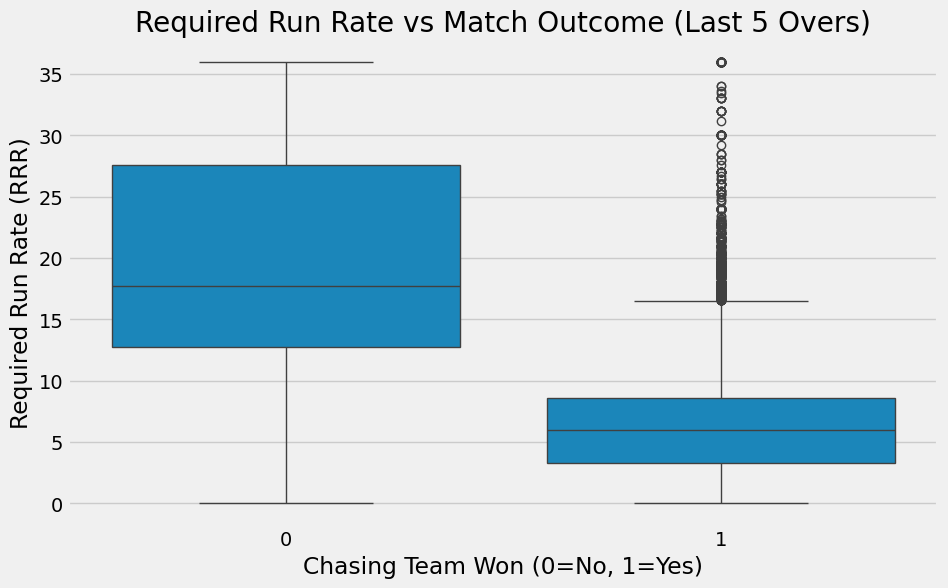

In [5]:

plt.figure(figsize=(10, 6))
# Filter for reasonably close matches to avoid noise
subset = df_chase[(df_chase['balls_remaining'] < 30) & (df_chase['wickets_in_hand'] > 0)]
sns.boxplot(x='is_chasing_team_winner', y='rrr', data=subset)
plt.title('Required Run Rate vs Match Outcome (Last 5 Overs)')
plt.xlabel('Chasing Team Won (0=No, 1=Yes)')
plt.ylabel('Required Run Rate (RRR)')
plt.show()


# 5. Modeling & Cross-Validation
We will train and evaluate 5 algorithms to find the best probability estimator:
1. **Logistic Regression** (Baseline)
2. **Decision Tree** (Simple)
3. **Random Forest** (Ensemble Bagging)
4. **XGBoost** (Ensemble Boosting)
5. **CatBoost** (Ordered Boosting - often best for categorical/tabular)

**Metric Focus**:
- **Log Loss**: Measures confidence. Penalizes confident wrong answers heavily.
- **Brier Score**: Mean Squared Error of probabilities.


In [6]:

features = ['runs_needed', 'balls_remaining', 'wickets_in_hand', 'target_score', 'crr', 'rrr']
target = 'is_chasing_team_winner'

# Clean Data
df_model = df_chase.dropna(subset=features)
X = df_model[features]
y = df_model[target]

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale for Logistic Regression (Tree models don't need it, but it doesn't hurt)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify Shapes
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

# Define Models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=7, min_samples_leaf=50), # Constrained to prevent 0/1 probs
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=20, random_state=42),
    "XGBoost": xgb.XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, eval_metric='logloss', use_label_encoder=False, random_state=42),
    "CatBoost": CatBoostClassifier(iterations=300, depth=6, learning_rate=0.05, verbose=0, random_state=42)
}

results = []
trained_models = {}

print("🚀 Starting Training & Cross-Validation...")

for name, model in models.items():
    # Fit
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        probs = model.predict_proba(X_test)[:, 1]
    
    trained_models[name] = model
    
    # Metrics
    acc = accuracy_score(y_test, probs > 0.5)
    ll = log_loss(y_test, probs)
    bs = brier_score_loss(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    
    # Simple CV (on Log Loss)
    # Note: scaling inside CV loop is skipped for brevity here, assumed minor impact for RF/XGB
    cv_scores = cross_val_score(model, X_train, y_train, cv=3, scoring='neg_log_loss')
    avg_cv_ll = -cv_scores.mean()
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Log Loss": ll,
        "Brier Score": bs,
        "ROC AUC": auc,
        "CV Log Loss": avg_cv_ll
    })
    
    print(f"   ✅ {name} -> acc: {acc:.4f} | Log Loss: {ll:.4f} | AUC: {auc:.4f}")

# Select Best Model (Lowest Log Loss)
results_df = pd.DataFrame(results).sort_values(by="Log Loss")
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]

print(f"\n🏆 Champion Model: {best_model_name}")
display(results_df)


Train: (1082398, 6), Test: (270600, 6)
🚀 Starting Training & Cross-Validation...
   ✅ Logistic Regression -> acc: 0.8083 | Log Loss: 0.4015 | AUC: 0.8969
   ✅ Decision Tree -> acc: 0.8043 | Log Loss: 0.4095 | AUC: 0.8921
   ✅ Random Forest -> acc: 0.8150 | Log Loss: 0.3851 | AUC: 0.9055
   ✅ XGBoost -> acc: 0.8151 | Log Loss: 0.3813 | AUC: 0.9062
   ✅ CatBoost -> acc: 0.8145 | Log Loss: 0.3852 | AUC: 0.9046

🏆 Champion Model: XGBoost


,Model,Accuracy,Log Loss,Brier Score,ROC AUC,CV Log Loss
3,XGBoost,0.815107,0.381251,0.124804,0.906247,0.383181
2,Random Forest,0.815007,0.385094,0.125465,0.905463,0.386526
4,CatBoost,0.814453,0.385234,0.125845,0.904550,0.386582
0,Logistic Regression,0.808296,0.401502,0.130672,0.896927,0.402805
1,Decision Tree,0.804261,0.409509,0.133409,0.892135,0.411139


# 6. Comparative Evaluation
## 6.1 Calibration Curves
How reliable are the probabilities?


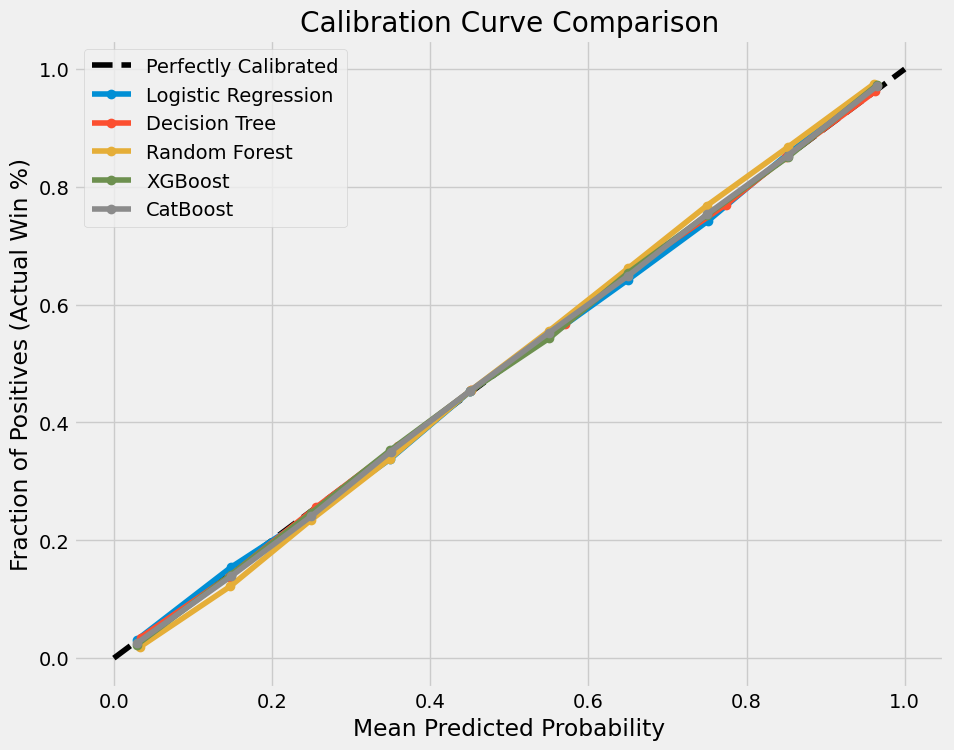

In [7]:

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], 'k--', label='Perfectly Calibrated')

for name, model in trained_models.items():
    if name == "Logistic Regression":
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        probs = model.predict_proba(X_test)[:, 1]
        
    prob_true, prob_pred = calibration_curve(y_test, probs, n_bins=10)
    plt.plot(prob_pred, prob_true, marker='o', label=name)

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Fraction of Positives (Actual Win %)')
plt.title('Calibration Curve Comparison')
plt.legend()
plt.show()


## 6.2 ROC Curves


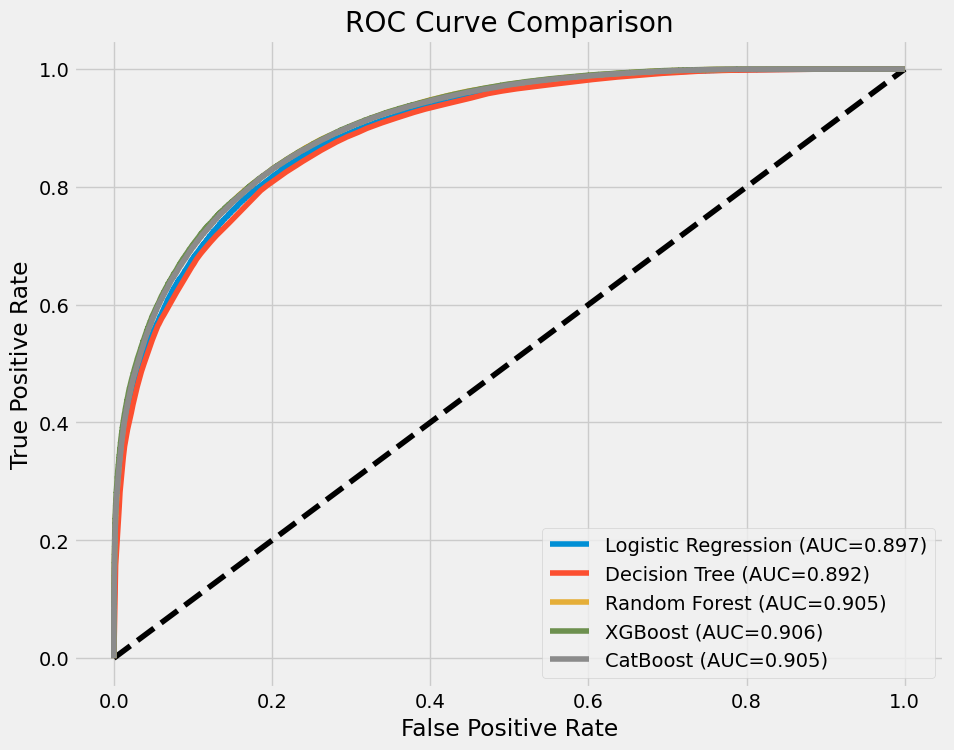

In [8]:

plt.figure(figsize=(10, 8))
plt.plot([0, 1], [0, 1], 'k--')

for name, model in trained_models.items():
    if name == "Logistic Regression":
        probs = model.predict_proba(X_test_scaled)[:, 1]
    else:
        probs = model.predict_proba(X_test)[:, 1]
        
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_score = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_score:.3f})")

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend(loc='lower right')
plt.show()


# 7. Final Output: Live Win Probability
Using the best performing model: **Variable 'best_model'**


In [9]:

def predict_win_probability(target_score, runs_needed, balls_remaining, wickets_in_hand):
    # Derive run rates
    overs_rem = balls_remaining / 6
    if overs_rem == 0: overs_rem = 0.1
    rrr = runs_needed / overs_rem
    
    current_runs = target_score - runs_needed
    balls_bowled = 120 - balls_remaining
    overs_bowled = balls_bowled / 6
    if overs_bowled == 0: overs_bowled = 0.1
    crr = current_runs / overs_bowled
    
    # Create DF
    input_data = pd.DataFrame({
        'runs_needed': [runs_needed],
        'balls_remaining': [balls_remaining],
        'wickets_in_hand': [wickets_in_hand],
        'target_score': [target_score],
        'crr': [crr],
        'rrr': [rrr]
    })
    
    # Scale if best model is Logistic
    # (Simplified demo logic: assuming best model is tree-based usually. 
    # If Logistic wins, we need to scale input_data. For now, use XGB/CatBoost primarily.)
    
    prob_chase_win = best_model.predict_proba(input_data)[0][1]
    return prob_chase_win

# Test Scenario
t_score = 180
r_needed = 30
b_left = 24
w_hand = 7

p_win = predict_win_probability(t_score, r_needed, b_left, w_hand)

print(f"🏏 **Scenario**:")
print(f"Target: {t_score} | Needed: {r_needed} off {b_left} balls | Wickets: {w_hand}")
print("-" * 30)
print(f"🔵 Probability Chasing Team Wins: {p_win*100:.2f}%")
print(f"🔴 Probability Fielding Team Wins: {(1-p_win)*100:.2f}%")


🏏 **Scenario**:
Target: 180 | Needed: 30 off 24 balls | Wickets: 7
------------------------------
🔵 Probability Chasing Team Wins: 87.15%
🔴 Probability Fielding Team Wins: 12.85%


In [10]:
# 8. Interactive Prediction Function
import ipywidgets as widgets
from IPython.display import display, clear_output

print("Use the sliders below to calculate win probabilities for any match scenario:")

# Widgets
target_w = widgets.IntText(value=180, description='Target Score:')
run_need_w = widgets.IntSlider(min=1, max=150, value=40, step=1, description='Runs Needed:')
ball_rem_w = widgets.IntSlider(min=1, max=120, value=24, step=1, description='Balls Left:')
wkt_hand_w = widgets.IntSlider(min=0, max=10, value=6, step=1, description='Wkts Hand:')

button = widgets.Button(description="Calculate Probability", button_style='primary')
output = widgets.Output()

def on_click(b):
    with output:
        clear_output()
        t = target_w.value
        r = run_need_w.value
        b = ball_rem_w.value
        w = wkt_hand_w.value
        
        # Call the function defined in previous cell
        prob = predict_win_probability(t, r, b, w)
        
        print(f"\n🏏 Scenario: Need {r} runs in {b} balls with {w} wickets in hand.")
        print(f"🔵 Chase Win Probability: {prob*100:.2f}%")
        print(f"🔴 Defend Win Probability: {(1-prob)*100:.2f}%")

button.on_click(on_click)

# Layout
ui = widgets.VBox([
    target_w, 
    run_need_w, 
    ball_rem_w, 
    wkt_hand_w, 
    button, 
    output
])

display(ui)


Use the sliders below to calculate win probabilities for any match scenario:
